# Chemotaxis

**Chemotaxis:** Directed movement in response to a chemical stimulus.

Needs:
- Sensing the chemicals in the environment (receptor-ligand binding/ enzyme kinetics)
- Coverting the sensed signal into intracellular concentration of key molecules (phosphorylation of flagallar motor/polymeration of actin)
- Convertion of the chemical changes into motion.

## Goals:
1. Revisiting ODE solvers to model enzyme kinetics.
2. Solving differential equations with explicit time dependence.
3. Building a stochastic spatial model involving diffusion.
4. Measuring properties of diffusion.

## Enzyme kinetics

Consider the reversible binding of a chemical in the environment ($S$) to a receptor on the cell ($E$). This binding produces a complex ($C$) which leads to the formation of a product ($P$). We can use differential equations to model this chemical process


$
\begin{align}
\begin{split}
\frac{dS}{dt} &= -k_+ SE + k_-C \\
\frac{dE}{dt} &= -k_+ SE + k_-C + k_f C\\
\frac{dC}{dt} &= k_+ SE - k_-C - k_fC\\
\frac{dP}{dt} &= k_f C
\end{split}
\end{align}
$

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Simulating Chemical Reactions</b> 
    
***
</div>


In [2]:
import numpy as np
from scipy import integrate
import matplotlib.pyplot as plt

def mm_dyn(y,t,pars):
    # mm_dyn(y,t,pars):
    # Simulates a full enzyme kinetics model 
    # Assign variables
    S, E, C, P = y[0], y[1], y[2], y[3]
    #core dynamics
    dydt = np.zeros(4)
    
    dydt[0] = -pars['kplus']*S*E + pars['kminus']*C
    dydt[1] = -pars['kplus']*S*E + pars['kminus']*C + pars['kf']*C
    dydt[2] = pars['kplus']*S*E - pars['kminus']*C - pars['kf']*C
    dydt[3] = pars['kf']*C 
    
    return dydt

### Simulating the dynamics

Use the following parameter values to simulate the chemical reaction:

$k_+ = 0.1 \text{s}^{-1}\mu\text{M}^{-1}$ (Binding rate)

$k_- = 100 \text{s}^{-1}$ (Unbinding rate)

$k_f = 1 \text{s}^{-1}$ (Forward reaction rate)

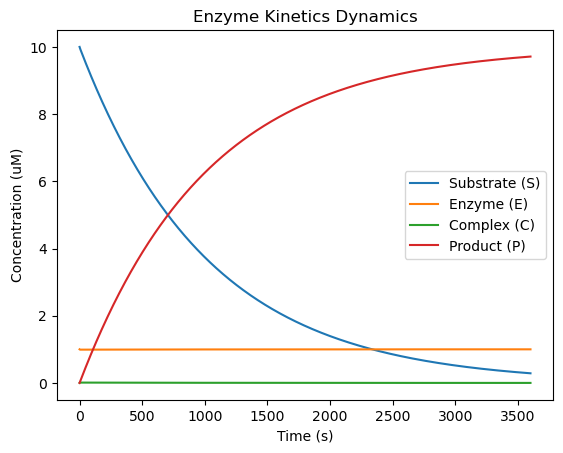

In [3]:
# Parameters in uM and s units
pars = {}
pars['kplus'] = 0.1
pars['kminus'] = 100
pars['kf'] = 1 

t0 = 0 #initial time
tf = 3600 # final time in seconds

S0 = 10 # initial substrate/ligand concentration in uM
E0 = 1 # initial enzyme/receptor concentration in uM

t = np.linspace(t0, tf, 1000) # time points to evaluate the solution

y = integrate.odeint(mm_dyn, [S0, E0, 0, 0], t, args=(pars,))

plt.plot(t, y[:,0], label='Substrate (S)')
plt.plot(t, y[:,1], label='Enzyme (E)')
plt.plot(t, y[:,2], label='Complex (C)')
plt.plot(t, y[:,3], label='Product (P)')
plt.xlabel('Time (s)')
plt.ylabel('Concentration (uM)')
plt.title('Enzyme Kinetics Dynamics')
plt.legend()
plt.show()

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Product dynamics</b> 
</div>
Compare the <i>rate</i> of product production, dP/dt, with the anticipated rate via the Michaelis-Menten approximation 

$$\frac{dP}{dt} \approx k_f E_0\frac{S(t)}{k_-/k_+ + S(t)}$$


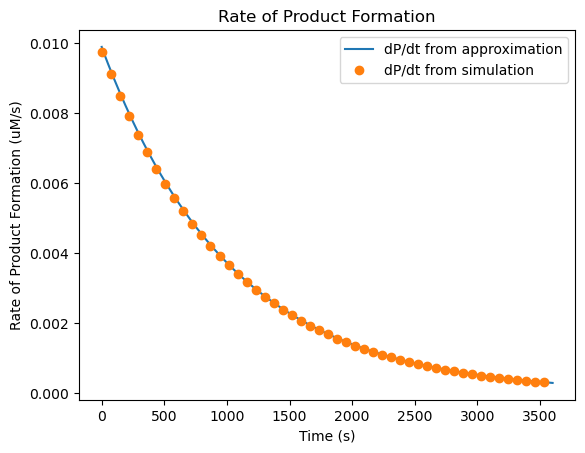

In [4]:
S = y[:,0]
E = y[:,1]
C = y[:,2]
P = y[:,3]

dPdt_mm = pars['kf']*(E+C)*S/(pars['kminus']/pars['kplus'] + S) #approximation from Michaelis-Menten

dPdt_simulated = (P[1:]-P[0:-1])/(t[1:]-t[0:-1]) # rate of product production from finite difference

plt.plot(t, dPdt_mm, label='dP/dt from approximation')
plt.plot(t[1::20], dPdt_simulated[0::20], 'o', label='dP/dt from simulation')
plt.xlabel('Time (s)')
plt.ylabel('Rate of Product Formation (uM/s)')
plt.title('Rate of Product Formation')
plt.legend()
plt.show()

### Time dependent functions in differential equations

So far, all the differential equations we've encountered did not have time explicitly in the equations.
But sometimes, that might be the case (eg. Addition of an inducer at a particular point in time in a gene regulatory circuit, flooding the medium with a chemoattractant).

We can easily implement this kind of time dependence using odeint (or equivalent functions in other programming languages).

Consider the mRNA dynamics equation:

$\frac{dm}{dt} = \beta (t) - \alpha m$,

where $\beta$(t) is the (time dependent) production rate of mRNA and $\alpha$ is the mRNA degradation rate.

Suppose mRNA production only happens when the gene is turned on, which happens until the first 10hrs of the experiment. Then, one way to simulate the system dynamics is to solve the equations:

$\frac{dm}{dt} = \beta_0 -\alpha m$, for $t \leq 10$ hr

and then solve the equation 

$\frac{dm}{dt} = -\alpha m$, for $t > 10$ hr

or,

we just solve the one equation 

$\frac{dm}{dt} = \beta_0 \Theta(10-t) - \alpha m$.

$\Theta(t)$ is the Heaviside function, which is 1 when t>0 and 0 otherwise.


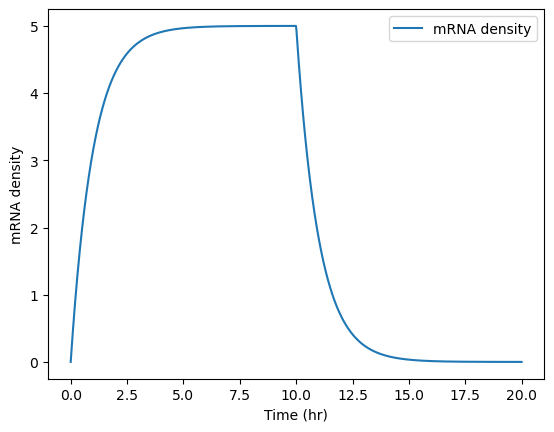

In [8]:
def pulse_production(m,t,pars):
    
    dmdt = (t<10)*pars['beta'] - pars['alpha']*m
    
    return dmdt

pars['beta'] = 5 # production rate in nM/hr
pars['alpha'] = 1 #degradation rate in /hr

m0 = 0
t0 = 0
tf = 20 # final time in hours
t = np.linspace(t0,tf,1000)

m = integrate.odeint(pulse_production,0,t,args = (pars,))

plt.plot(t,m, label = 'mRNA density')
plt.xlabel('Time (hr)')
plt.ylabel('mRNA density')
plt.legend()
plt.show()

<div class="alert alert-block alert-warning">
<b>Challenge Problem: Time-dependent Input to Dynamical Systems</b> 
</div>

Instead of the simple on-off switch in the example, simulate $\beta(t) = \beta_{\text{mid}}(1+sin(2\pi t))$


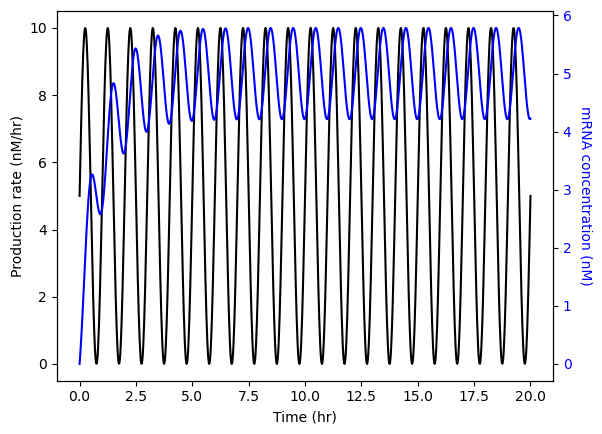

In [6]:
def sin_production(m,t,pars):
    
    dmdt = pars['beta_mid']*(1+np.sin(2*np.pi*t)) - pars['alpha']*m
    return dmdt

pars = {}
pars['beta_mid'] = 5 # in nM/hr
pars['alpha'] = 1 # in /hr

t0 = 0 # initial time in hours
tf = 20 # final time in hours
t = np.linspace(t0,tf,1000)
m = integrate.odeint(sin_production,0,t,args = (pars,))

fig, ax1 = plt.subplots()

cl = 'k'
ax1.plot(t,pars['beta_mid']*(1+np.sin(2*np.pi*t)), color = cl, linestyle = '-', label = 'Production Rate')
ax1.set_xlabel('Time (hr)')
ax1.set_ylabel('Production rate (nM/hr)', color = cl)
ax1.tick_params(axis = 'y', labelcolor = cl)

#Add twin axes
ax2 = ax1.twinx()

cl = 'b'

ax2.set_ylabel('mRNA concentration (nM)', color=cl, rotation=-90, labelpad=15)
ax2.plot(t,m, color = cl, linestyle = '-', label = 'mRNA concentration')
ax2.tick_params(axis = 'y', labelcolor = cl)

plt.show()

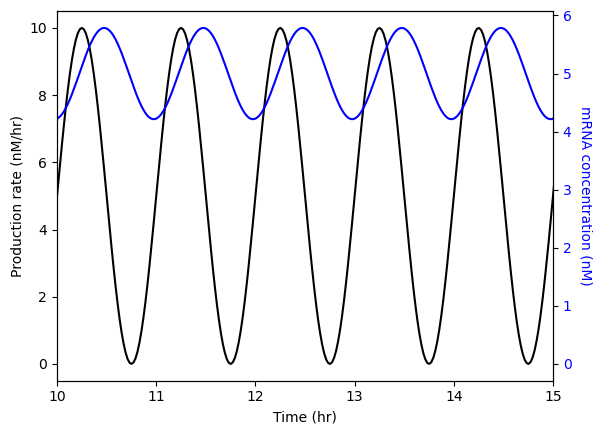

In [7]:
fig, ax1 = plt.subplots()

cl = 'k'
ax1.plot(t,pars['beta_mid']*(1+np.sin(2*np.pi*t)), color = cl, linestyle = '-', label = 'Production Rate')
ax1.set_xlabel('Time (hr)')
ax1.set_ylabel('Production rate (nM/hr)', color = cl)
ax1.tick_params(axis = 'y', labelcolor = cl)
ax1.set_xlim(10,15)
#Add twin axes
ax2 = ax1.twinx()

cl = 'b'

ax2.set_ylabel('mRNA concentration (nM)', color=cl, rotation=-90, labelpad=15)
ax2.plot(t,m, color = cl, linestyle = '-', label = 'mRNA concentration')
ax2.tick_params(axis = 'y', labelcolor = cl)

plt.show()